# Questions
1. Which Gender had the higest survival rate?

   **Answer:** Female (74.20 %).

2. Which passenger class had the lowest survival rate?

   **Answer:** 3rd Class

3. What does Survived = 0 represent?

   **Answer:** Passenger did not survive


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
df = pd.read_csv("Titanic-Dataset.csv")

In [14]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [15]:
df.shape

(891, 12)

In [16]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [17]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


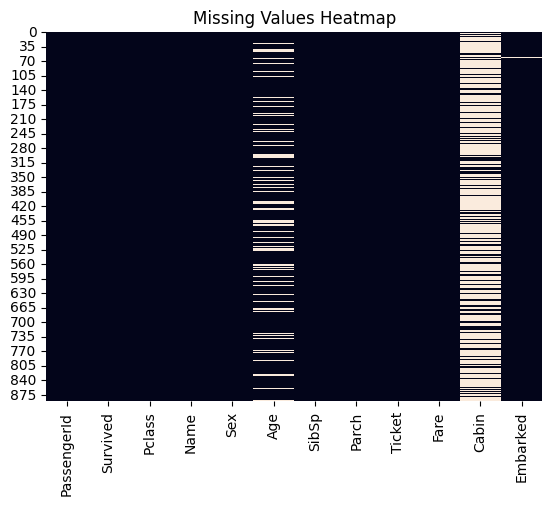

In [19]:
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values Heatmap")
plt.show()

In [23]:
df.duplicated().sum()

np.int64(0)

In [24]:
df["Age"] = df['Age'].fillna(df['Age'].mean())
df["Embarked"] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [46]:
df.drop(columns=['Cabin'], inplace=True)

In [47]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
FamilySize     0
dtype: int64

In [25]:
df["Sex"].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

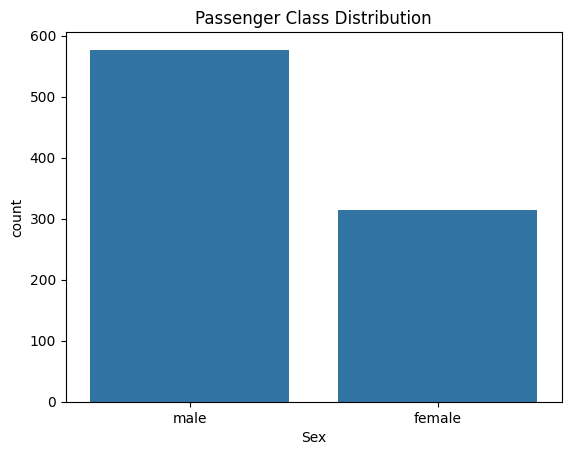

In [26]:
sns.countplot(x='Sex', data=df)
plt.title("Passenger Class Distribution")
plt.show()

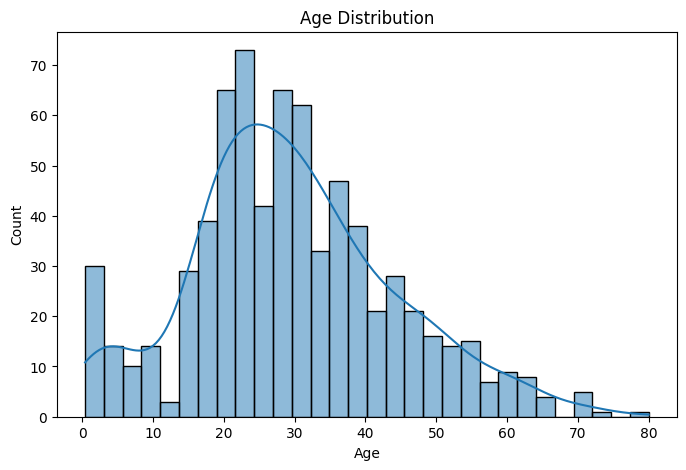

In [21]:
plt.figure(figsize=(8,5))
sns.histplot(df['Age'], bins=30, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")   
plt.show()

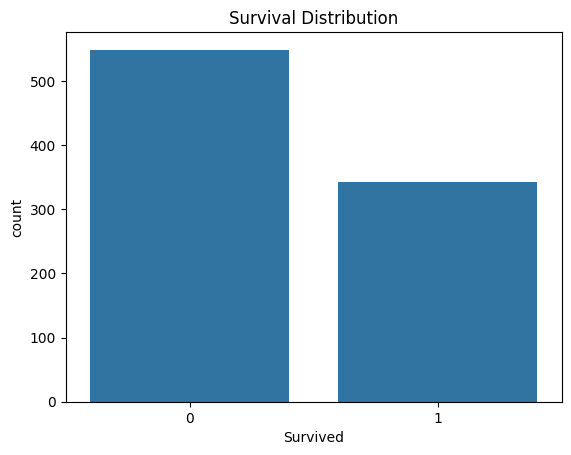

In [27]:
sns.countplot(x='Survived', data=df)
plt.title("Survival Distribution")
plt.show()

In [30]:
df.groupby('Sex')['Survived'].value_counts()

Sex     Survived
female  1           233
        0            81
male    0           468
        1           109
Name: count, dtype: int64

In [31]:
df.groupby('Sex')['Survived'].mean() * 100

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

In [32]:
df.groupby("Pclass")['Survived'].mean() * 100

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

In [33]:
df.groupby("Pclass")["Fare"].mean()

Pclass
1    84.154687
2    20.662183
3    13.675550
Name: Fare, dtype: float64

In [34]:
df.groupby("Embarked")['Survived'].mean() * 100

Embarked
C    55.357143
Q    38.961039
S    33.900929
Name: Survived, dtype: float64

In [35]:
df.groupby("Pclass").agg({
    'Age': 'mean',
    'Fare': 'mean',
    'Survived': 'mean',
    'PassengerId': 'count'
})

,Age,Fare,Survived,PassengerId
Pclass,,,,
1,37.048118,84.154687,0.629630,216
2,29.866958,20.662183,0.472826,184
3,26.403259,13.675550,0.242363,491


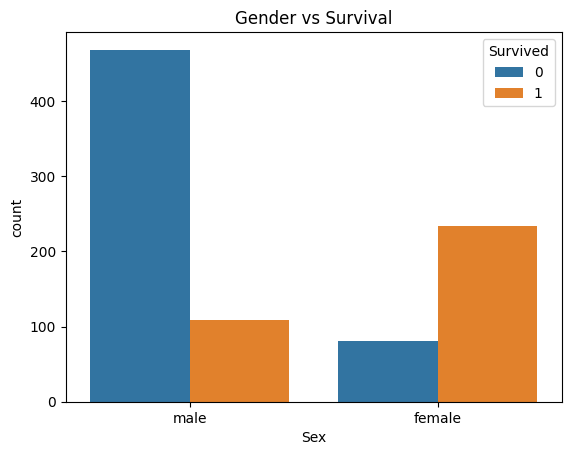

In [36]:
sns.countplot(x='Sex', data=df, hue='Survived')
plt.title("Gender vs Survival")
plt.show()

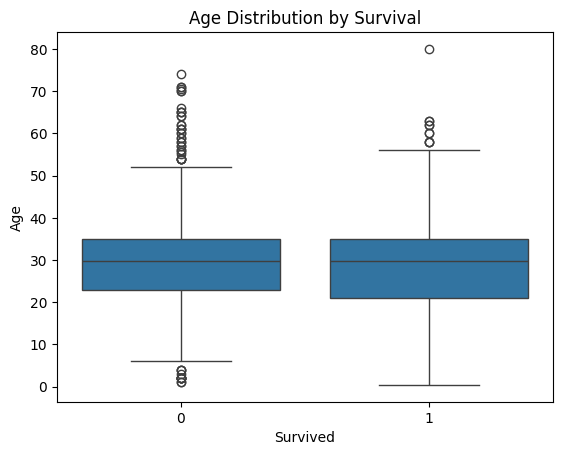

In [37]:
sns.boxplot(x='Survived', y='Age', data=df)
plt.title("Age Distribution by Survival")
plt.show()

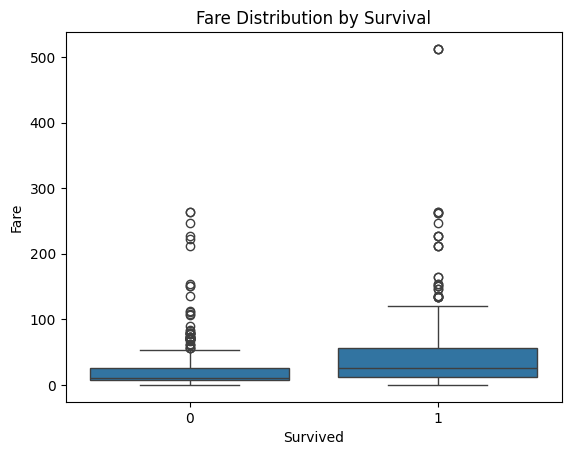

In [38]:
sns.boxplot(x='Survived', y='Fare', data=df)
plt.title("Fare Distribution by Survival")
plt.show()

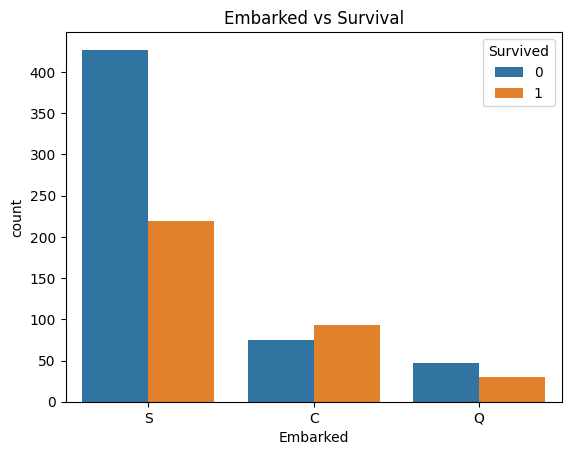

In [39]:
sns.countplot(x='Embarked', hue= 'Survived', data=df)
plt.title("Embarked vs Survival")
plt.show()

In [40]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

In [42]:
df.groupby("FamilySize")['Survived'].agg(['mean', 'count'])

,mean,count
FamilySize,,
1,0.303538,537
2,0.552795,161
3,0.578431,102
4,0.724138,29
5,0.200000,15
6,0.136364,22
7,0.333333,12
8,0.000000,6
11,0.000000,7


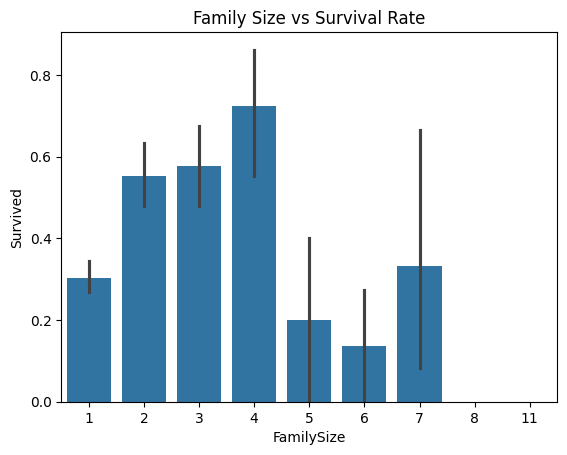

In [43]:
sns.barplot(x='FamilySize', y='Survived', data=df)
plt.title("Family Size vs Survival Rate")
plt.show()

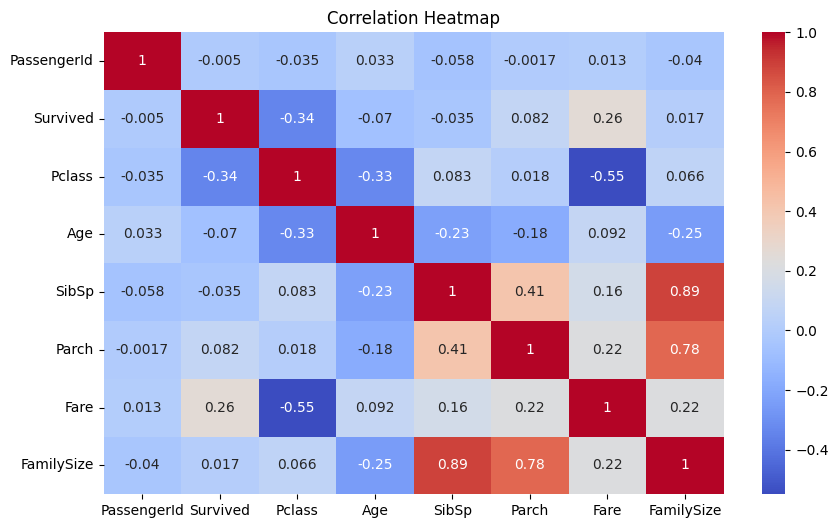

In [44]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    df.select_dtypes(include= "number").corr(),
    annot=True,
    cmap='coolwarm',
)
plt.title("Correlation Heatmap")
plt.show()